# HW3 Image Classification
## We strongly recommend that you run with [Kaggle](https://www.kaggle.com/t/86ca241732c04da99aca6490080bae73) for this homework

If you have any questions, please contact the TAs via TA hours, NTU COOL, or email to mlta-2023-spring@googlegroups.com

# Check GPU Type

In [18]:
!nvidia-smi

Fri Nov  6 01:04:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.42                 KMD Version: 617.42        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   46C    P4             26W /  115W |    1519MiB /  12227MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Get Data
Notes: if the links are dead, you can download the data directly from Kaggle and upload it to the workspace, or you can use the Kaggle API to directly download the data into colab.


In [19]:
# Download Link
# Link 1 (Dropbox): https://www.dropbox.com/s/up5q1gthsz3v0dq/food-11.zip?dl=0
# Link 2 (Google Drive): https://drive.google.com/file/d/1tbGNwk1yGoCBdu4Gi_Cia7EJ9OhubYD9/view?usp=share_link
# Link 3: Kaggle Competition.

# (1) dropbox link
# !wget -O food11.zip https://www.dropbox.com/s/up5q1gthsz3v0dq/food-11.zip?dl=0

# (2) google drive link
!pip install gdown --upgrade
!gdown --id '1tbGNwk1yGoCBdu4Gi_Cia7EJ9OhubYD9' --output food11.zip

usage: gdown [-h] [-V] [-O OUTPUT] [-q] [--proxy PROXY] [--speed SPEED]
             [--cookies FILE] [--cookies-from-browser BROWSER] [--no-cookies]
             [--no-check-certificate] [--continue] [--retries N] [--folder]
             [--json] [--format FORMAT] [--user-agent USER_AGENT]
             [--timeout SECONDS]
             url_or_id
gdown: error: unrecognized arguments: --id


In [20]:
! unzip food11.zip

'unzip' �����ڲ����ⲿ���Ҳ���ǿ����еĳ���
���������ļ���


# Import Packages

In [21]:
_exp_name = "exp_17"

In [22]:
# Import necessary packages.
import numpy as np
import pandas as pd
import torch
import os
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
# "ConcatDataset" and "Subset" are possibly useful when doing semi-supervised learning.
from torch.utils.data import ConcatDataset, DataLoader, Subset, Dataset
from torchvision.datasets import DatasetFolder, VisionDataset
# This is for the progress bar.
from tqdm.auto import tqdm
import random

In [23]:
myseed = 6666  # set a random seed for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(myseed)
torch.manual_seed(myseed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(myseed)

# Transforms
Torchvision provides lots of useful utilities for image preprocessing, data *wrapping* as well as data augmentation.

Please refer to PyTorch official website for details about different transforms.

In [24]:
# Normally, We don't need augmentations in testing and validation.
# All we need here is to resize the PIL image and transform it into Tensor.
test_tfm = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# However, it is also possible to use augmentation in the testing phase.
# You may use train_tfm to produce a variety of images and then test using ensemble methods
train_tfm = transforms.Compose([
    # Resize the image into a fixed shape (height = width = 128)
    # transforms.Resize((128, 128)),
    transforms.RandomResizedCrop(128, scale=(0.7,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomPerspective(distortion_scale=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    # transforms.RandomCrop(128, padding=16, padding_mode='reflect'),

    # ToTensor() should be the last one of the transforms.
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Datasets
The data is labelled by the name, so we load images and label while calling '__getitem__'

In [25]:
class FoodDataset(Dataset):

    def __init__(self,path,tfm=test_tfm,files = None):
        super(FoodDataset).__init__()
        self.path = path
        self.files = sorted([os.path.join(path,x) for x in os.listdir(path) if x.endswith(".jpg")])
        if files != None:
            self.files = files

        self.transform = tfm

    def __len__(self):
        return len(self.files)

    def __getitem__(self,idx):
        fname = self.files[idx]
        im = Image.open(fname)
        im = self.transform(im)

        try:
            label = int(os.path.basename(fname).split("_")[0])
        except:
            label = -1 # test has no label

        return im,label

# Model

In [26]:
class Classifier(nn.Module):
    def __init__(self):
        super(Classifier, self).__init__()
        # torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        # torch.nn.MaxPool2d(kernel_size, stride, padding)
        # input 維度 [3, 128, 128]
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 16, 3, 1, 1),  # [16, 128, 128]
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [16, 64, 64]每次看2×2，看完移动两格

            nn.Conv2d(16, 32, 3, 1, 1), # [32, 64, 64]
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [32, 32, 32]

            nn.Conv2d(32, 64, 3, 1, 1), # [64, 32, 32]
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [64, 16, 16]

            nn.Conv2d(64, 128, 3, 1, 1), # [128, 16, 16]
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 256, 3, 1, 1), # [256, 16, 16]
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [256, 8, 8]

            nn.Conv2d(256, 512, 3, 1, 1), # [512, 8, 8]
            nn.BatchNorm2d(512),
            nn.ReLU(),

            nn.Conv2d(512, 1024, 3, 1, 1), # [1024, 8, 8]
            nn.BatchNorm2d(1024),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [1024, 4, 4]

        )
        self.fc = nn.Sequential(
            nn.Linear(1024*4*4, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 11)
        )

    def forward(self, x):
        out = self.cnn(x)
        out = out.view(out.size()[0], -1)
        return self.fc(out)

# Configurations

In [27]:
# "cuda" only when GPUs are available.
device = "cuda" if torch.cuda.is_available() else "cpu"

# Initialize a model, and put it on the device specified.
import torchvision

# model = Classifier().to(device)   # 旧的：自己写的 CNN
model = torchvision.models.resnet18(weights=None, num_classes=11).to(device)

# The number of batch size.
batch_size = 64

# The number of training epochs.
n_epochs = 80

# If no improvement in 'patience' epochs, early stop.验证集多少次没有创新高就停止训练
patience = 20

# For the classification task, we use cross-entropy as the measurement of performance.
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Initialize optimizer, you may fine-tune some hyperparameters such as learning rate on your own.
# optimizer = torch.optim.Adam(model.parameters(), lr=0.0003, weight_decay=1e-5)   # 旧的
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

# Dataloader

In [28]:
# Construct train and valid datasets.
# The argument "loader" tells how torchvision reads the data.
train_set = FoodDataset("./train", tfm=train_tfm)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
valid_set = FoodDataset("./valid", tfm=test_tfm)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)

# Start Training

In [29]:
# Initialize trackers, these are not parameters and should not be changed
stale = 0
best_acc = 0

for epoch in range(n_epochs):

    # ---------- Training ----------
    # Make sure the model is in train mode before training.
    model.train()

    # These are used to record information in training.
    train_loss = []
    train_accs = []

    for batch in tqdm(train_loader):

        # A batch consists of image data and corresponding labels.
        imgs, labels = batch
        #imgs = imgs.half()
        #print(imgs.shape,labels.shape)

        # Forward the data. (Make sure data and model are on the same device.)
        logits = model(imgs.to(device))

        # Calculate the cross-entropy loss.
        # We don't need to apply softmax before computing cross-entropy as it is done automatically.
        loss = criterion(logits, labels.to(device))

        # Gradients stored in the parameters in the previous step should be cleared out first.
        optimizer.zero_grad()

        # Compute the gradients for parameters.
        loss.backward()

        # Clip the gradient norms for stable training.
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=10)

        # Update the parameters with computed gradients.
        optimizer.step()

        # Compute the accuracy for current batch.
        acc = (logits.argmax(dim=-1) == labels.to(device)).float().mean()

        # Record the loss and accuracy.
        train_loss.append(loss.item())
        train_accs.append(acc)

    train_loss = sum(train_loss) / len(train_loss)
    train_acc = sum(train_accs) / len(train_accs)

    # Print the information.
    print(f"[ Train | {epoch + 1:03d}/{n_epochs:03d} ] loss = {train_loss:.5f}, acc = {train_acc:.5f}")
    scheduler.step()

    # ---------- Validation ----------
    # Make sure the model is in eval mode so that some modules like dropout are disabled and work normally.
    model.eval()

    # These are used to record information in validation.
    valid_loss = []
    valid_accs = []

    # Iterate the validation set by batches.
    for batch in tqdm(valid_loader):

        # A batch consists of image data and corresponding labels.
        imgs, labels = batch
        #imgs = imgs.half()

        # We don't need gradient in validation.
        # Using torch.no_grad() accelerates the forward process.
        with torch.no_grad():
            logits = model(imgs.to(device))

        # We can still compute the loss (but not the gradient).
        loss = criterion(logits, labels.to(device))

        # Compute the accuracy for current batch.
        acc = (logits.argmax(dim=-1) == labels.to(device)).float().mean()

        # Record the loss and accuracy.
        valid_loss.append(loss.item())
        valid_accs.append(acc)
        #break

    # The average loss and accuracy for entire validation set is the average of the recorded values.
    valid_loss = sum(valid_loss) / len(valid_loss)
    valid_acc = sum(valid_accs) / len(valid_accs)

    # Print the information.
    print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f}")


    # update logs
    if valid_acc > best_acc:
        with open(f"./{_exp_name}_log.txt","a"):
            print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f} -> best")
    else:
        with open(f"./{_exp_name}_log.txt","a"):
            print(f"[ Valid | {epoch + 1:03d}/{n_epochs:03d} ] loss = {valid_loss:.5f}, acc = {valid_acc:.5f}")


    # save models
    if valid_acc > best_acc:
        print(f"Best model found at epoch {epoch}, saving model")
        torch.save(model.state_dict(), f"{_exp_name}_best.ckpt") # only save best to prevent output memory exceed error
        best_acc = valid_acc
        stale = 0
    else:
        stale += 1
        if stale > patience:
            print(f"No improvment {patience} consecutive epochs, early stopping")
            break

  0%|          | 0/157 [00:00<?, ?it/s]

[ Train | 001/080 ] loss = 2.12953, acc = 0.28453


  0%|          | 0/57 [00:00<?, ?it/s]

[ Valid | 001/080 ] loss = 1.98265, acc = 0.32674
[ Valid | 001/080 ] loss = 1.98265, acc = 0.32674 -> best
Best model found at epoch 0, saving model


  0%|          | 0/157 [00:00<?, ?it/s]

[ Train | 002/080 ] loss = 1.96471, acc = 0.35430


... (310 outputs left out)

  0%|          | 0/157 [00:00<?, ?it/s]

[ Train | 080/080 ] loss = 0.58574, acc = 0.97840


  0%|          | 0/57 [00:00<?, ?it/s]

[ Valid | 080/080 ] loss = 1.04495, acc = 0.80046
[ Valid | 080/080 ] loss = 1.04495, acc = 0.80046


# Dataloader for test

In [30]:
# Construct test datasets.
# The argument "loader" tells how torchvision reads the data.
test_set = FoodDataset("./test", tfm=test_tfm)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

# Testing and generate prediction CSV

In [31]:
# model_best = Classifier().to(device)   # 旧的：自己写的 CNN，和 exp_17 存的 ResNet18 权重对不上
model_best = torchvision.models.resnet18(weights=None, num_classes=11).to(device)
model_best.load_state_dict(torch.load(f"{_exp_name}_best.ckpt"))
model_best.eval()
prediction = []
with torch.no_grad():
    for data,_ in tqdm(test_loader):
        test_pred = model_best(data.to(device))
        test_label = np.argmax(test_pred.cpu().data.numpy(), axis=1)
        prediction += test_label.squeeze().tolist()

  0%|          | 0/47 [00:00<?, ?it/s]

In [32]:
# create test csv
def pad4(i):
    return "0"*(4-len(str(i)))+str(i)
df = pd.DataFrame()
df["Id"] = [pad4(i) for i in range(len(test_set))]
df["Category"] = prediction
df.to_csv("submission.csv",index = False)

# Cross Validation + Ensemble（Boss 路线）

课件的 Boss baseline 给的提示是 **Cross Validation + Ensemble**。

思路：
1. 把 train(10000) + valid(3643) 合并成 13643 张，切成 5 折
2. 每一折用 4 份训练、1 份验证，各训一个 ResNet18，共 5 个模型
3. 5 个模型对测试集各预测一次，概率取平均 → 比单模型更稳

代价：训练时间是单模型的 5 倍。

In [33]:
# ========== 第 1 步：5 折交叉验证训练 ==========
# 注意：这一步很慢，5 折 × 80 轮，大概 6~10 小时
# 建议先在下面把 n_epochs 临时改成 2 跑一遍，确认没问题再改回 80

import numpy as np
import torchvision
from torch.utils.data import ConcatDataset, Subset

# 同一份数据准备两个版本：训练版带增强，验证版只做 Resize + Normalize
full_for_train = ConcatDataset([
    FoodDataset("./train", tfm=train_tfm),
    FoodDataset("./valid", tfm=train_tfm),
])
full_for_eval = ConcatDataset([
    FoodDataset("./train", tfm=test_tfm),
    FoodDataset("./valid", tfm=test_tfm),
])
print("合并后总样本数:", len(full_for_train))   # 应该是 13643

n_folds = 5
all_idx = np.arange(len(full_for_train))
np.random.default_rng(myseed).shuffle(all_idx)
fold_splits = np.array_split(all_idx, n_folds)

cv_best_accs = []

for fold in range(n_folds):
    print("=" * 55)
    print(f"第 {fold+1}/{n_folds} 折")
    print("=" * 55)

    val_idx = fold_splits[fold]
    tr_idx = np.concatenate([fold_splits[i] for i in range(n_folds) if i != fold])

    tr_set = Subset(full_for_train, tr_idx)
    va_set = Subset(full_for_eval, val_idx)
    tr_loader = DataLoader(tr_set, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    va_loader = DataLoader(va_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
    print(f"训练 {len(tr_set)} 张，验证 {len(va_set)} 张")

    # 每一折都用全新的模型，从头训
    model_f = torchvision.models.resnet18(weights=None, num_classes=11).to(device)
    criterion_f = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_f = torch.optim.AdamW(model_f.parameters(), lr=1e-3, weight_decay=0.05)
    scheduler_f = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_f, T_max=n_epochs)

    best_acc_f = 0.0
    stale_f = 0
    ckpt_f = f"cv_fold{fold+1}_best.ckpt"

    for epoch in range(n_epochs):
        # ---- 训练 ----
        model_f.train()
        for imgs, labels in tqdm(tr_loader, desc=f"fold{fold+1} train"):
            imgs, labels = imgs.to(device), labels.to(device)
            loss = criterion_f(model_f(imgs), labels)
            optimizer_f.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model_f.parameters(), max_norm=10)
            optimizer_f.step()
        scheduler_f.step()

        # ---- 验证 ----
        model_f.eval()
        correct = total = 0
        with torch.no_grad():
            for imgs, labels in va_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                correct += (model_f(imgs).argmax(-1) == labels).sum().item()
                total += labels.size(0)
        acc = correct / total
        print(f"  epoch {epoch+1:03d}/{n_epochs}: val acc {acc:.5f}")

        if acc > best_acc_f:
            best_acc_f = acc
            torch.save(model_f.state_dict(), ckpt_f)
            stale_f = 0
        else:
            stale_f += 1
            if stale_f > patience:
                print(f"  连续 {patience} 轮无进步，第 {fold+1} 折提前停止")
                break

    cv_best_accs.append(best_acc_f)
    print(f"第 {fold+1} 折完成，最优 val acc = {best_acc_f:.5f}，模型已存到 {ckpt_f}")

    del model_f, optimizer_f, scheduler_f
    torch.cuda.empty_cache()

print("=" * 55)
print("5 折结果:", [f"{a:.4f}" for a in cv_best_accs])
print(f"平均准确率: {np.mean(cv_best_accs):.5f}")
print("=" * 55)


合并后总样本数: 13643
第 1/5 折
训练 10914 张，验证 2729 张


fold1 train:   0%|          | 0/171 [00:00<?, ?it/s]

  epoch 001/80: val acc 0.27080


fold1 train:   0%|          | 0/171 [00:00<?, ?it/s]

  epoch 002/80: val acc 0.39172


fold1 train:   0%|          | 0/171 [00:00<?, ?it/s]

... (791 outputs left out)

fold5 train:   0%|          | 0/171 [00:00<?, ?it/s]

  epoch 079/80: val acc 0.82075


fold5 train:   0%|          | 0/171 [00:00<?, ?it/s]

  epoch 080/80: val acc 0.81195
第 5 折完成，最优 val acc = 0.82075，模型已存到 cv_fold5_best.ckpt
5 折结果: ['0.8300', '0.8047', '0.8095', '0.8072', '0.8207']
平均准确率: 0.81441


In [34]:
# ========== 第 2 步：5 个模型集成预测 ==========
# 每张测试图让 5 个模型各猜一次，把 5 个概率分布取平均，再取最大
# 这一步很快，5 个模型轮流加载，显存不会叠加

test_set_cv = FoodDataset("./test", tfm=test_tfm)
test_loader_cv = DataLoader(test_set_cv, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

probs_sum = None
for fold in range(5):
    m = torchvision.models.resnet18(weights=None, num_classes=11).to(device)
    m.load_state_dict(torch.load(f"cv_fold{fold+1}_best.ckpt"))
    m.eval()

    probs_this = []
    with torch.no_grad():
        for data, _ in tqdm(test_loader_cv, desc=f"fold{fold+1} predict"):
            probs_this.append(torch.softmax(m(data.to(device)), dim=1).cpu())
    probs_this = torch.cat(probs_this, dim=0)

    probs_sum = probs_this if probs_sum is None else probs_sum + probs_this
    print(f"fold{fold+1} 预测完成")

    del m
    torch.cuda.empty_cache()

ensemble_pred = (probs_sum / 5).argmax(dim=1).tolist()
print(f"集成预测完成，共 {len(ensemble_pred)} 张")

# ========== 第 3 步：写成提交文件 ==========
def pad4_cv(i):
    return "0" * (4 - len(str(i))) + str(i)

df_cv = pd.DataFrame()
df_cv["Id"] = [pad4_cv(i) for i in range(len(test_set_cv))]
df_cv["Category"] = ensemble_pred
df_cv.to_csv("submission_cv.csv", index=False)
print("已写入 submission_cv.csv，可以去 Kaggle 提交了")

fold1 predict:   0%|          | 0/47 [00:00<?, ?it/s]

fold1 预测完成


fold2 predict:   0%|          | 0/47 [00:00<?, ?it/s]

fold2 预测完成


fold3 predict:   0%|          | 0/47 [00:00<?, ?it/s]

fold3 预测完成


fold4 predict:   0%|          | 0/47 [00:00<?, ?it/s]

fold4 预测完成


fold5 predict:   0%|          | 0/47 [00:00<?, ?it/s]

fold5 预测完成
集成预测完成，共 3000 张
已写入 submission_cv.csv，可以去 Kaggle 提交了


# Q1. Augmentation Implementation
## Implement augmentation by finishing train_tfm in the code with image size of your choice.
## Directly copy the following block and paste it on GradeScope after you finish the code
### Your train_tfm must be capable of producing 5+ different results when given an identical image multiple times.
### Your  train_tfm in the report can be different from train_tfm in your training code.


In [35]:
train_tfm = transforms.Compose([
    # Resize the image into a fixed shape (height = width = 128)
    transforms.Resize((128, 128)),
    # You can add some transforms here.
    transforms.RandomHorizontalFlip(),
    #随机左右旋转
    transforms.RandomRotation(15),
    #随机旋转15°°
    transforms.ColorJitter(brightness=0.2, constrast=0.2),
    #:随机轻微调亮度/对比度——模拟不同拍摄光线条件
    transforms.ToTensor(),
])

TypeError: ColorJitter.__init__() got an unexpected keyword argument 'constrast'

# Q2. Visual Representations Implementation
## Visualize the learned visual representations of the CNN model on the validation set by implementing t-SNE (t-distributed Stochastic Neighbor Embedding) on the output of both top & mid layers (You need to submit 2 images).


In [ ]:
import torch
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib.cm as cm
import torch.nn as nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load the trained model
model = Classifier().to(device)
state_dict = torch.load(f"{_exp_name}_best.ckpt")
model.load_state_dict(state_dict)
model.eval()

print(model)

Classifier(
  (cnn): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1

100%|██████████| 57/57 [00:10<00:00,  5.62it/s]


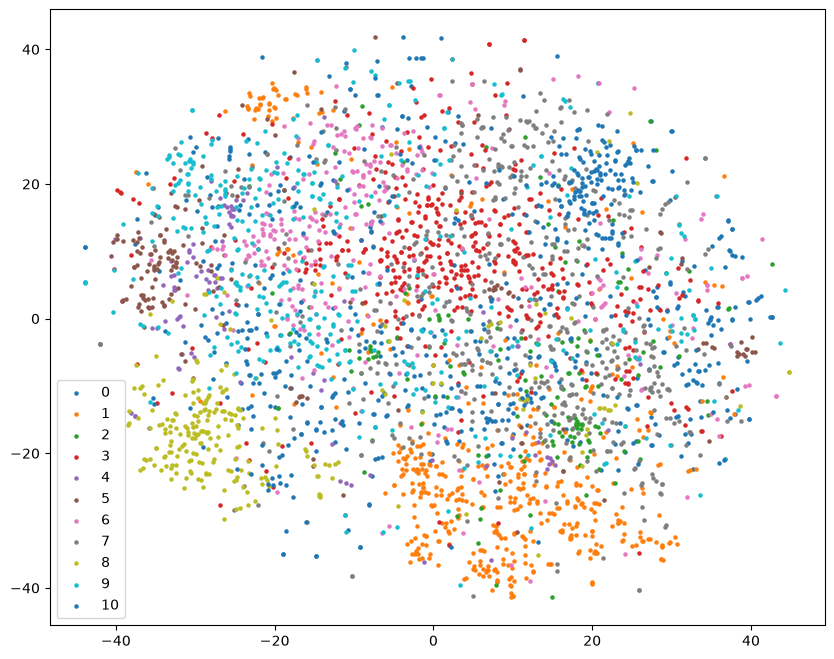

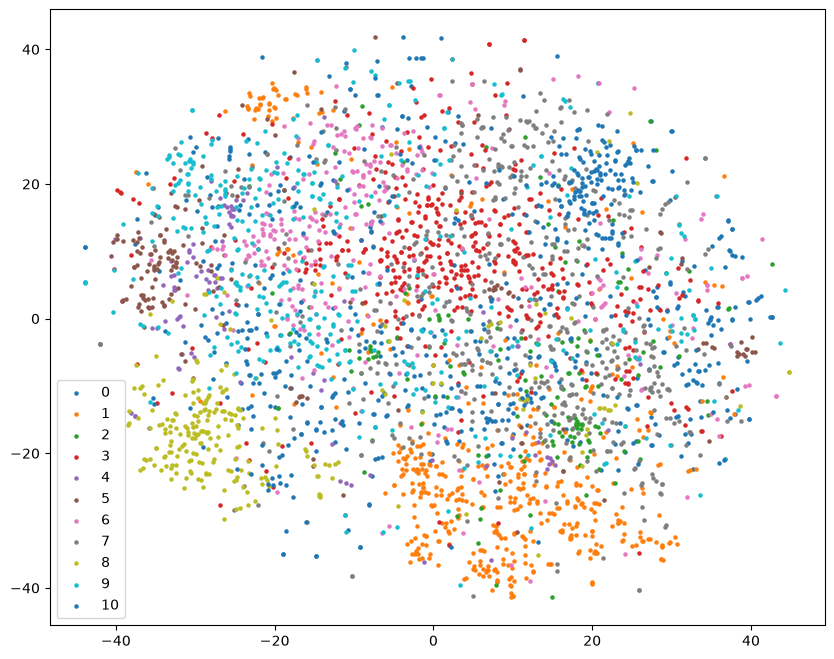

In [ ]:
# Load the vaildation set defined by TA
valid_set = FoodDataset("./valid", tfm=test_tfm)
valid_loader = DataLoader(valid_set, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

# Extract the representations for the specific layer of model
index = 20 # You should find out the index of layer which is defined as "top" or 'mid' layer of your model.
features = []
labels = []
for batch in tqdm(valid_loader):
    imgs, lbls = batch
    with torch.no_grad():
        logits = model.cnn[:index](imgs.to(device))
        logits = logits.view(logits.size()[0], -1)
    labels.extend(lbls.cpu().numpy())
    logits = np.squeeze(logits.cpu().numpy())
    features.extend(logits)

features = np.array(features)
colors_per_class = cm.rainbow(np.linspace(0, 1, 11))

# Apply t-SNE to the features
features_tsne = TSNE(n_components=2, init='pca', random_state=42).fit_transform(features)

# Plot the t-SNE visualization
plt.figure(figsize=(10, 8))
for label in np.unique(labels):
    plt.scatter(features_tsne[labels == label, 0], features_tsne[labels == label, 1], label=label, s=5)
plt.legend()
plt.show()

plt.figure(figsize=(10, 8))
for label in np.unique(labels):
    plt.scatter(features_tsne[labels == label, 0], features_tsne[labels == label, 1], label=label, s=5)
plt.legend()
plt.show()

# 我的实验记录

HW3 和 HW2 不一样：图像分类更容易过拟合（train_acc 和 valid_acc 的差距会变大），而且能改的地方不只是超参数，还有数据增强（train_tfm，对应 Q1）和模型结构本身（cnn 层数/宽度，或者换成预训练模型）。
记录的时候把"改动类型"分开标，回顾时候才知道这次的进步/退步到底是调参、换了增强方式、还是改了模型结构导致的。

改 `_exp_name` 记得同步改下面的实验记录里的 exp_name，不然 `{_exp_name}_best.ckpt` 会被覆盖，之前的模型就找不回来了。

In [ ]:
# 字段说明：
# exp_name                  -> 对应 cell 7 的 _exp_name，这次实验保存的 ckpt 文件名前缀
# 改动类型                   -> 数据增强 / 模型结构 / 训练超参数（三选一，方便回顾时筛选）
# 具体改动                   -> 这次具体改了什么（例如 train_tfm 加了 RandomHorizontalFlip）
# train_acc / valid_acc      -> 最后一轮（或 early stop 时最优）的训练/验证准确率
# 过拟合迹象(train-valid)     -> train_acc - valid_acc，差距变大说明过拟合更严重，不一定是模型变强了
# 猜测 / 结果是否符合猜测      -> 改之前先写猜测，跑完再填结果，不要跑完再补猜测
#
# 「过拟合迹象」不用手填，填完 train_acc 和 valid_acc 会自动算出来

log = []

# ---------- 实验 0：官方基线 ----------
log.append({
    "exp_name": "sample",
    "改动类型": "基线",
    "具体改动": "官方 sample code 原始配置：train_tfm 只 Resize(128,128)，CNN 默认结构，n_epochs=8，lr=0.0003",
    "train_acc": 0.77249,
    "valid_acc": 0.61773,
    "过拟合迹象(train-valid)": "0.15476",      # 自动计算
    "情况": "",
    "结论": "",
})

# ---------- 实验 1 ----------
log.append({
    "exp_name": "exp_1",
    "改动类型": "model",
    "具体改动": "第 5 个卷积 512→1024 通道（BN 跟着改 1024），全连接改成 1024*4*4→2048→512→11（原来 512*4*4→1024→512→11）；参数量 1283 万 → 4089 万",
    "train_acc": "0.73388",                    
    "valid_acc": "0.58572",
    "过拟合迹象(train-valid)": "",      # 自动计算
    "情况": "改动以后参数层扩大了4倍，卷积部分几乎翻了一倍，结果过拟合现象加重，模型开始背答案了，其实基线的时候就已经过拟合了",
    "结论": "",
})

# ---------- 实验 2 ----------
log.append({
    "exp_name": "exp_2",
    "改动类型": "model",
    "具体改动": "实验一的改动恢复，全连接层从512*4*4->1024->512->11变成512*4*4->512->256->11变成",
    "train_acc": "0.78185",                    
    "valid_acc": "0.62860",
    "过拟合迹象(train-valid)": "0.15325",      # 自动计算
    "情况": "先试试把全连接层改小能不能有效防止过拟合",
    "结论": "过拟合还在，但是关键是train_vaild的数值越来越大，说明有可能是轮数不够。（见笔记Hw_3对过拟合的阐释。调高epoch",
})

# ---------- 实验 3 ----------
log.append({
    "exp_name": "exp_3",
    "改动类型": "Hyperparameter",
    "具体改动": "epoch8->16",
    "train_acc": "0.96377",                    
    "valid_acc": "0.61569",
    "过拟合迹象(train-valid)": "0.34808",      # 自动计算
    "情况": "epoch次数太多了，loss一直上升",
    "结论": "降低一点epoch",
})

# ---------- 实验 4 ----------
log.append({
    "exp_name": "exp_4",
    "改动类型": "Hyperparameter",
    "具体改动": "epoch16->12",
    "train_acc": "0.90754",                    
    "valid_acc": "0.64434",
    "过拟合迹象(train-valid)": "0.26320",      # 自动计算
    "情况": "还是有过拟合，虽然好了点，但是这个时候已经是一个拐点了，所以epoch的改变目前结束",
    "结论": "还是回到model部分",
})

# ---------- 实验 5 ----------
log.append({
    "exp_name": "exp_5",
    "改动类型": "model",
    "具体改动": "通道整体缩窄并多加一个卷积块：卷积通道 64/128/256/512/512 → 16/32/64/128/256/512，共 6 个卷积块（原 5 个），最后 pool 两次到 512*2*2；全连接 512*2*2→512→256→11（原 512*4*4→1024→512→11）；参数量 1283 万 → 276 万",
    "train_acc": "0.96437",                    
    "valid_acc": "0.51248",
    "过拟合迹象(train-valid)": "0.45189",      # 自动计算
    "情况": "一次性改了三个条件!!!通道数（64/128/256/512/512 → 16/32/64/128/256/512）；卷积块数（5 → 6）；全连接结构（8192→1024→512 → 2048→512→256）",
    "结论": "可以确定的是再同样参数量下，同样的参数预算，深窄网络比浅宽网络能表达更复杂的函数",
})

# ---------- 实验 6 ----------
log.append({
    "exp_name": "exp_6",
    "改动类型": "model",
    "具体改动": "全连接部分恢复出厂设置",
    "train_acc": "0.93899",                    
    "valid_acc": "0.54883",
    "过拟合迹象(train-valid)": "0.39016",      # 自动计算
    "情况": "valid_loss 翻了一倍，但 valid_acc 只差几个点。意思是：模型对错误答案的置信度变得非常高。",
    "结论": "卷积骨干部分的参数太少了，加深了但是流失的参数弥补不了，同时最后的池化太猛了",
})

# ---------- 实验 7 ----------
log.append({
    "exp_name": "exp_7",
    "改动类型": "model",
    "具体改动": "卷积参数部分扩大，删除部分池化",
    "train_acc": "0.78434",                    
    "valid_acc": "0.52224",
    "过拟合迹象(train-valid)": "0.26210",      # 自动计算
    "情况": "前 9 轮欠拟合——2.75 亿参数，但只有 1,872 次更新机会，训练集才拟合到 0.67。第 9 轮验证见顶，后 3 轮转为过拟合，最终 train 0.78 / valid 0.52",
    "结论": "删池化让全连接输入从 8,192 变成 262,144，单层参数涨到 2.68 亿。这层占了模型 97.5% 的参数，却既最难训练（梯度被 26 万个输入稀释）、又最容易记住训练集（每个位置一套权重）",
})

# ---------- 实验 8 ----------
log.append({
    "exp_name": "exp_8",
    "改动类型": "model",
    "具体改动": "增加部分池化到最后4*4",
    "train_acc": "0.84604",                    
    "valid_acc": "0.61585",
    "过拟合迹象(train-valid)": "0.23019	",      # 自动计算
    "情况": "training loss还在快速下降区间，说明没有收敛，12轮还不够",
    "结论": "深而窄的卷积需要更多轮才能把特征学出来，12 轮不够",
})

# ---------- 实验 9 ----------
log.append({
    "exp_name": "exp_9",
    "改动类型": "hyperparameters",
    "具体改动": "epoch12->16",
    "train_acc": "0.92476",                    
    "valid_acc": "0.61295",
    "过拟合迹象(train-valid)": "0.31181	",      # 自动计算
    "情况": "12 轮时这个模型已经到顶了，后面的轮次只是让它更会背训练集。",
    "结论": "考虑让图片进行一下transform",
})

# ---------- 实验 10 ----------
log.append({
    "exp_name": "exp_10",
    "改动类型": "transforms",
    "具体改动": "图片随机旋转15°并且概率把图片左右旋转同时随机轻微改变对比度用来模拟不同拍摄条件",
    "train_acc": "0.77239",                    
    "valid_acc": "0.64953",
    "过拟合迹象(train-valid)": "0.12286	",      # 自动计算
    "情况": "目前为止最好的一次",
    "结论": "对图像加了变换确实好了很多",
})

# ---------- 实验 11 ----------
log.append({
    "exp_name": "exp_11",
    "改动类型": "transforms",
    "具体改动": "加上随机垂直翻转",
    "train_acc": "0.67994",                    
    "valid_acc": "0.64512",
    "过拟合迹象(train-valid)": "0.03482	",      # 自动计算
    "情况": "差距从 0.123 掉到 0.035，但 valid 也降了 1.1 个点，垂直翻转并没有带来收益，而且最后一轮还是最高，没有收敛",
    "结论": "应该考虑到一个实际问题，上下颠倒再真实世界基本不会出现，而且验证集里面的照片也不会上下颠倒",
})

# ---------- 实验 12 ----------
log.append({
    "exp_name": "exp_12",
    "改动类型": "transforms",
    "具体改动": "删去随机垂直翻转，添加randomcrop让食物在画面里面的位置随机偏移",
    "train_acc": "0.69735",                    
    "valid_acc": "0.66296 ",
    "过拟合迹象(train-valid)": "0.03439",      # 自动计算
    "情况": "最高点出现在最后一轮，训练集还没有到上限，验证loss还在下降，过拟合基本没有动",
    "结论": "epoch不够，添加",
})

# ---------- 实验 13 ----------
log.append({
    "exp_name": "exp_13",
    "改动类型": "configurations",
    "具体改动": "epoch16->30",
    "train_acc": "0.72671 ",                    
    "valid_acc": "0.67308 ",
    "过拟合迹象(train-valid)": "0.05363",      # 自动计算
    "情况": "目前方法已经到头了",
    "结论": "开始添加transform方法",
})

# ---------- 实验 14 ----------
log.append({
    "exp_name": "exp_14",
    "改动类型": "transforms",
    "具体改动": "epoch->32，加上透视变换RandomPerspective",
    "train_acc": "0.74473 ",                    
    "valid_acc": "0.67363 ",
    "过拟合迹象(train-valid)": "0.07110",      # 自动计算
    "情况": "比实验13多了好多轮，但是并没有太多的进步并且过拟合的时候差值更大",
    "结论": "加上透视并没有好很多",
})

# ---------- 实验 15 ----------
log.append({
    "exp_name": "exp_15",
    "改动类型": "transforms，图片进行缩放，模拟真实拍摄情况",
    "具体改动": "epoch32不变，RandomResizedCrop(128, scale=(0.7,1.0)) 替换掉现在的 Resize+RandomCrop",
    "train_acc": "0.75926 ",                    
    "valid_acc": "0.69876 ",
    "过拟合迹象(train-valid)": "0.06050	",      # 自动计算
    "情况": "train还没有达到饱和，过拟合差距仍然很大，增大epoch",
    "结论": "增大epoch",
})

# ---------- 实验 16 ----------
log.append({
    "exp_name": "exp_16",
    "改动类型": "transforms",
    "具体改动": "epoch32->80",
    "train_acc": "0.91690",                    
    "valid_acc": "0.75127",
    "过拟合迹象(train-valid)": "0.16563",      # 自动计算
    "情况": "大幅增强",
    "结论": "CNN基本到头来，换成ResNet",
})

# ---------- 实验 17 ----------
log.append({
    "exp_name": "exp_17",
    "改动类型": "model + hyperparameters",
    "具体改动": "模型从自定义 CNN 换成 torchvision.models.resnet18(weights=None, num_classes=11)，不加载预训练权重，从零开始训练（利用残差连接解决深层网络训练不动的问题）；优化器 Adam→AdamW，lr 0.0003→1e-3，weight_decay 1e-5→0.05；新增 CosineAnnealingLR(T_max=n_epochs) 学习率调度，每轮训练后 scheduler.step()；train_tfm/test_tfm 末尾新增 Normalize(ImageNet mean/std)，之前所有实验都漏掉了这一步",
    "train_acc": 0.96984,
    "valid_acc": 0.78668,
    "过拟合迹象(train-valid)": "0.18316",      # 自动计算
    "情况": "最优模型出现在第 72 轮（共 80 轮），之后 8 轮 valid 在 0.78 附近小幅波动，没有像 CNN 那样掉头下跌；train 已经到 0.97，差距比 exp_16 大，但 valid 绝对值更高，是实质性的提升",
    "结论": "换 ResNet18 这一步有效，valid 从 exp_16 的 0.7513 涨到 0.7867，+3.5 个点，离 Strong baseline(0.814) 还差 2.7 个点",
})

# ---------- 实验 18 ----------
log.append({
    "exp_name": "exp_18",
    "改动类型": "configuration",
    "具体改动": "添加label smoothing0.1",
    "train_acc": "0.97840",                    
    "valid_acc": "0.80046",
    "过拟合迹象(train-valid)": "0.17794	",      # 自动计算
    "情况": "",
    "结论": "",
})

# ---------- 实验 19 ----------
log.append({
    "exp_name": "exp_19",
    "改动类型": "训练方式 + 集成",
    "具体改动": "5 折交叉验证 + 模型集成：把 train(10000) 和 valid(3643) 合并成 13643 张，随机切 5 折（每折训练 10914 张、验证 2729 张）；每一折都从零训练一个 ResNet18(weights=None, num_classes=11)，超参数与 exp_18 完全一致（AdamW lr=1e-3、weight_decay=0.05、CosineAnnealingLR、label_smoothing=0.1、80 轮）；共得到 5 个模型 cv_fold1~5_best.ckpt；预测时 5 个模型各输出一次 softmax 概率，取平均后 argmax 得到最终类别，写入 submission_cv.csv",
    "train_acc": "",      # 交叉验证没有统一的训练集准确率，留空
    "valid_acc": 0.81441, # 5 折验证准确率的平均值
    "过拟合迹象(train-valid)": "",      # 自动计算（train_acc 为空，本行不计算）
    "情况": "5 折分别达到 0.8300 / 0.8047 / 0.8095 / 0.8072 / 0.8207，平均 0.81441；第 1 折最高（0.8300），说明数据切分对结果有约 2 个点的影响；训练从 02:00 跑到 06:02，共约 4 小时，平均每折 48 分钟，比预估的 8 小时快一半",
    "结论": "5 折平均已经踩上 Strong baseline(0.814)，超过 exp_18 单模型的 0.8025；集成预测结果写入 submission_cv.csv，Kaggle 实际分数待提交后回填",
})



def add_gap(records):
    """只要 train_acc 和 valid_acc 是数字，就自动算出两者的差"""
    for r in records:
        t, v = r.get("train_acc"), r.get("valid_acc")
        try:
            r["过拟合迹象(train-valid)"] = round(float(t) - float(v), 5)
        except (TypeError, ValueError):
            r["过拟合迹象(train-valid)"] = ""
    return records


log = add_gap(log)
pd.DataFrame(log)


,exp_name,改动类型,具体改动,train_acc,valid_acc,过拟合迹象(train-valid),情况,结论
0,sample,基线,"官方 sample code 原始配置：train_tfm 只 Resize(128,128...",0.77249,0.61773,0.15476,,
1,exp_1,model,第 5 个卷积 512→1024 通道（BN 跟着改 1024），全连接改成 1024*4*...,0.73388,0.58572,0.14816,改动以后参数层扩大了4倍，卷积部分几乎翻了一倍，结果过拟合现象加重，模型开始背答案了，其实基...,
2,exp_2,model,实验一的改动恢复，全连接层从512*4*4->1024->512->11变成512*4*4-...,0.78185,0.62860,0.15325,先试试把全连接层改小能不能有效防止过拟合,过拟合还在，但是关键是train_vaild的数值越来越大，说明有可能是轮数不够。（见笔记H...
3,exp_3,Hyperparameter,epoch8->16,0.96377,0.61569,0.34808,epoch次数太多了，loss一直上升,降低一点epoch
4,exp_4,Hyperparameter,epoch16->12,0.90754,0.64434,0.26320,还是有过拟合，虽然好了点，但是这个时候已经是一个拐点了，所以epoch的改变目前结束,还是回到model部分
5,exp_5,model,通道整体缩窄并多加一个卷积块：卷积通道 64/128/256/512/512 → 16/32...,0.96437,0.51248,0.45189,一次性改了三个条件!!!通道数（64/128/256/512/512 → 16/32/64/...,可以确定的是再同样参数量下，同样的参数预算，深窄网络比浅宽网络能表达更复杂的函数
6,exp_6,model,全连接部分恢复出厂设置,0.93899,0.54883,0.39016,valid_loss 翻了一倍，但 valid_acc 只差几个点。意思是：模型对错误答案的...,卷积骨干部分的参数太少了，加深了但是流失的参数弥补不了，同时最后的池化太猛了
7,exp_7,model,卷积参数部分扩大，删除部分池化,0.78434,0.52224,0.26210,"前 9 轮欠拟合——2.75 亿参数，但只有 1,872 次更新机会，训练集才拟合到 0.6...","删池化让全连接输入从 8,192 变成 262,144，单层参数涨到 2.68 亿。这层占了..."
8,exp_8,model,增加部分池化到最后4*4,0.84604,0.61585,0.23019,training loss还在快速下降区间，说明没有收敛，12轮还不够,深而窄的卷积需要更多轮才能把特征学出来，12 轮不够
9,exp_9,hyperparameters,epoch12->16,0.92476,0.61295,0.31181,12 轮时这个模型已经到顶了，后面的轮次只是让它更会背训练集。,考虑让图片进行一下transform
